In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas as pd

# 修改为你的学号
STUDENT_ID = 20244080330

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]      {STUDENT_ID}")
print(f"[机器指纹]  {MACHINE_FP}")
print(f"[RUN_ID]    {RUN_ID}")

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False
np.random.seed(42)

[Conda 环境] base
[学号]      20244080330
[机器指纹]  778d3bae6fe7565c
[RUN_ID]    20244080330-778d3bae6fe7565c


### 实验1：NumPy数组、数据类型与索引
1. 创建整数、浮点数、布尔类型ndarray，输出`dtype`、`shape`、`ndim`。
> NumPy ndarray数组**所有元素必须是同一数据类型**，内存连续；
> Python列表可以存放任意不同类型的数据元素。

2. `np.arange(12)`生成一维数组，通过`reshape()`改变形状。
> reshape变形约束：**数组总元素数量必须保持不变**。

3. 数组索引：取指定行、指定列、条件布尔索引筛选大于6的元素。
4. 布尔索引：使用`|`、`&`或者`np.logical_or`、`np.logical_and`完成多条件筛选。
5. 乘法区分：
- `*` / `np.multiply()`：**逐元素乘法**，对应位置元素相乘
- `@` / `np.matmul()`：**矩阵乘法**，遵循线性代数矩阵运算规则

In [2]:
# 1. 创建整数、浮点、布尔ndarray
arr_int = np.array([1, 2, 3, 4], dtype=int)
arr_float = np.array([1.1, 2.2, 3.3, 4.4], dtype=float)
arr_bool = np.array([True, False, True], dtype=bool)
print("====整数数组====")
print(arr_int, f"dtype={arr_int.dtype}, shape={arr_int.shape}, ndim={arr_int.ndim}")
print("====浮点数组====")
print(arr_float, f"dtype={arr_float.dtype}, shape={arr_float.shape}, ndim={arr_float.ndim}")
print("====布尔数组====")
print(arr_bool, f"dtype={arr_bool.dtype}, shape={arr_bool.shape}, ndim={arr_bool.ndim}")

# 解释：numpy数组是同类型，内存连续；Python列表可以存放任意不同类型元素

# 2. np.arange(12)变形
a = np.arange(12)
a_34 = a.reshape(3,4)
a_232 = a.reshape(2,3,2)
print("\n====原始一维数组====\n", a)
print("\n====reshape(3,4)====\n", a_34)
print("\n====reshape(2,3,2)====\n", a_232)
print("reshape条件：总元素数量不变，12 = 3*4 = 2*3*2")

#3. 索引 (3,4)数组 a_34
print("\n====索引操作====")
row2 = a_34[1, :]
col1_3 = a_34[:, 0:3]
gt6 = a_34[a_34>6]
print("第2行：", row2, "shape:", row2.shape)
print("第1~3列：\n", col1_3, "shape:", col1_3.shape)
print("大于6的元素：", gt6, "shape:", gt6.shape)

#4. np.arange(10) 布尔筛选
arr10 = np.arange(10)
cond1 = arr10[(arr10 < 2) | (arr10 >7)]
cond2 = arr10[np.logical_and(arr10>3, arr10<7)]
print("\n====布尔筛选====")
print("小于2或者大于7：", cond1)
print("大于3并且小于7：", cond2)

#5. 逐元素乘法 vs 矩阵乘法
m1 = np.array([[1,2],[3,4]])
m2 = np.array([[5,6],[7,8]])
star = m1 * m2
multiply = np.multiply(m1, m2)
at = m1 @ m2
matmul = np.matmul(m1, m2)
print("\n====乘法对比====")
print("* 逐元素相乘：\n", star)
print("np.multiply：\n", multiply)
print("@ 矩阵乘法：\n", at)
print("np.matmul：\n", matmul)

====整数数组====
[1 2 3 4] dtype=int32, shape=(4,), ndim=1
====浮点数组====
[1.1 2.2 3.3 4.4] dtype=float64, shape=(4,), ndim=1
====布尔数组====
[ True False  True] dtype=bool, shape=(3,), ndim=1

====原始一维数组====
 [ 0  1  2  3  4  5  6  7  8  9 10 11]

====reshape(3,4)====
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

====reshape(2,3,2)====
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
reshape条件：总元素数量不变，12 = 3*4 = 2*3*2

====索引操作====
第2行： [4 5 6 7] shape: (4,)
第1~3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape: (3, 3)
大于6的元素： [ 7  8  9 10 11] shape: (5,)

====布尔筛选====
小于2或者大于7： [0 1 8 9]
大于3并且小于7： [4 5 6]

====乘法对比====
* 逐元素相乘：
 [[ 5 12]
 [21 32]]
np.multiply：
 [[ 5 12]
 [21 32]]
@ 矩阵乘法：
 [[19 22]
 [43 50]]
np.matmul：
 [[19 22]
 [43 50]]


### 实验2：随机抽样、统计与缺失值
1. 正态分布生成模拟成绩，`np.clip()`限制分数区间0‑100，输出样本统计指标。
2. `np.random.choice`实现不放回抽样：均匀抽样、按数值大小加权抽样。
3. `np.random.shuffle()`原地打乱原数组；`np.random.permutation()`返回新数组，**原数组不会被修改**。
4. 缺失值`np.nan`：普通`.mean()`遇到NaN结果直接为NaN；必须使用`np.nanmean()`忽略缺失做统计。统计缺失样本数量，观察NaN对统计函数的破坏。
5. 将带缺失的成绩与序号构造内存DataFrame，供后续实验使用，不写入磁盘文件。

In [3]:
#1. 生成1000个成绩，均值70，标准差10，限制0~100
score = np.random.normal(loc=70, scale=10, size=1000)
score = np.clip(score, 0, 100)
print("====成绩统计====")
print(f"样本数:{len(score)}, 最小值:{score.min():.2f}, 最大值:{score.max():.2f}")
print(f"均值:{score.mean():.2f}, 标准差:{score.std():.2f}, 极差:{score.max()-score.min():.2f}")

#2. 不放回抽样：均匀抽样 & 加权抽样
pop = np.arange(1,11)
sample_uniform = np.random.choice(pop, size=5, replace=False)
weight = pop / pop.sum()
sample_weighted = np.random.choice(pop, size=5, replace=False, p=weight)
print("\n====抽样====")
print("均匀不放回抽样：", sample_uniform)
print("按数值大小加权抽样：", sample_weighted)

#3. shuffle原地打乱 / permutation不改变原数组
ori = np.arange(10)
arr_shuffle = ori.copy()
np.random.shuffle(arr_shuffle)
arr_perm = np.random.permutation(ori)
print("\n====打乱对比====")
print("原始数组：", ori)
print("shuffle原地打乱后：", arr_shuffle)
print("permutation新数组：", arr_perm)

#4. 设置第10、20、30个值为NaN，对比均值
score_nan = score.copy()
score_nan[[9,19,29]] = np.nan
nan_count = np.isnan(score_nan).sum()
mean_normal = score_nan.mean()
mean_nan = np.nanmean(score_nan)
print("\n====缺失值====")
print(f"缺失数量：{nan_count}")
print(f"普通mean()（含NaN）：{mean_normal}")
print(f"np.nanmean忽略NaN均值：{mean_nan:.2f}")

#5. 转为DataFrame，给实验4使用
df_exp4 = pd.DataFrame({
    "idx": np.arange(len(score_nan)),
    "score": score_nan
})
print("\n准备给实验4的df（前5行）：")
print(df_exp4.head())

====成绩统计====
样本数:1000, 最小值:37.59, 最大值:100.00
均值:70.18, 标准差:9.76, 极差:62.41

====抽样====
均匀不放回抽样： [ 4  9  2  6 10]
按数值大小加权抽样： [10  2  8  9  6]

====打乱对比====
原始数组： [0 1 2 3 4 5 6 7 8 9]
shuffle原地打乱后： [7 0 5 4 1 8 9 2 6 3]
permutation新数组： [0 4 7 6 9 5 1 3 8 2]

====缺失值====
缺失数量：3
普通mean()（含NaN）：nan
np.nanmean忽略NaN均值：70.20

准备给实验4的df（前5行）：
   idx      score
0    0  74.967142
1    1  68.617357
2    2  76.476885
3    3  85.230299
4    4  67.658466


### 实验3：SciPy数值计算与Matplotlib可视化
1. `scipy.linalg.solve()`求解线性方程组，矩阵乘法代入验证解是否正确。
2. `scipy.optimize.root()`求解方程 $x^2-2=0$，设置不同初始猜测，分别求正负根，查看求解状态与函数残差。
3. `scipy.optimize.minimize()`求 $f(x)=x^2+x+2$ 的极小点，与解析解 $x=-0.5$ 对比。
4. 生成两组正态模拟样本，`scipy.stats.ttest_ind()`做独立样本t检验；在显著性水平0.05下判断两组均值是否存在显著差异。

绘图要求：图表必须包含标题、坐标轴标签、图例。
- 子图1：有效成绩直方图；子图2：成绩箱线图
- 同一坐标系绘制 $y=x、y=x^2、y=x^3，0\le x \le5$ 函数曲线

====方程组求解====
解：x=2.00, y=3.00
验算 A@sol： [9. 8.]

====方程x²-2=0====
正根：成功？ True 值： [1.41421356] 函数值： [-8.8817842e-16]
负根：成功？ True 值： [-1.41421356] 函数值： [-8.8817842e-16]

====函数极小值====
极小点x： [-0.50000001] 极小值： 1.75
解析解：x=-0.5，最小值1.75

====独立样本t检验====
t统计量=-6.5170, p值=0.0000
p<0.05，拒绝原假设，两组均值存在显著差异


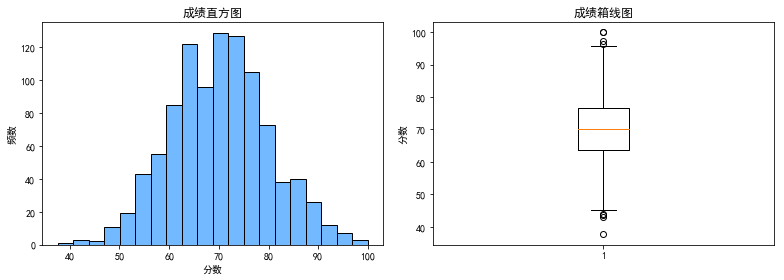

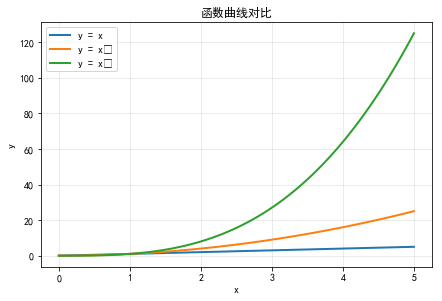

In [5]:
from scipy.linalg import solve
from scipy.optimize import root, minimize
from scipy.stats import ttest_ind

#1. 解方程组 3x + y =9 ; x +2y =8
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
sol = solve(A,b)
print("====方程组求解====")
print(f"解：x={sol[0]:.2f}, y={sol[1]:.2f}")
print("验算 A@sol：", A @ sol)

#2. x²-2=0，正负根
def f(x):
    return x**2 - 2
root_pos = root(f, x0=1)
root_neg = root(f, x0=-1)
print("\n====方程x²-2=0====")
print("正根：成功？", root_pos.success, "值：", root_pos.x, "函数值：", f(root_pos.x))
print("负根：成功？", root_neg.success, "值：", root_neg.x, "函数值：", f(root_neg.x))

#3. f(x)=x²+x+2求极小
def fun(x):
    return x**2 + x + 2
res_min = minimize(fun, x0=0)
print("\n====函数极小值====")
print("极小点x：", res_min.x, "极小值：", res_min.fun)
print("解析解：x=-0.5，最小值1.75")

#4. t检验，两组样本各100
g1 = np.random.normal(loc=0, scale=1, size=100)
g2 = np.random.normal(loc=1, scale=1, size=100)
t_stat, pval = ttest_ind(g1,g2)
print("\n====独立样本t检验====")
print(f"t统计量={t_stat:.4f}, p值={pval:.4f}")
if pval < 0.05:
    print("p<0.05，拒绝原假设，两组均值存在显著差异")
else:
    print("p≥0.05，不能拒绝原假设，无显著差异")

# ========== 绘图部分（两张子图：直方图+箱线图） ==========
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11,4))
valid_score = score[~np.isnan(score_nan)]
ax1.hist(valid_score, bins=20, color="#73b9ff", edgecolor="black")
ax1.set_title("成绩直方图")
ax1.set_xlabel("分数")
ax1.set_ylabel("频数")

ax2.boxplot(valid_score)
ax2.set_title("成绩箱线图")
ax2.set_ylabel("分数")
plt.tight_layout()
plt.show()

# ========== 函数曲线 y=x，y=x²，y=x³ 0<=x<=5 ==========
x = np.linspace(0, 5, 100)
y1 = x
y2 = x**2
y3 = x**3
plt.figure(figsize=(7,4.5))
plt.plot(x,y1,label="y = x", linewidth=2)
plt.plot(x,y2,label="y = x²", linewidth=2)
plt.plot(x,y3,label="y = x³", linewidth=2)
plt.title("函数曲线对比")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 实验4：pandas Series、DataFrame 数据处理
1. 使用给定字典构建DataFrame，将Name设为行索引；新增`Total`三科总分、`Average`三科平均分；输出索引、列名、前3行、描述统计信息。
2. `loc`按标签读取、`iloc`按数字位置读取记录；筛选平均分不低于80的学生。
3. `mean(axis=0)`：按**列方向**聚合，求各科成绩均值；
`mean(axis=1)`：按**行方向**聚合，求每个学生三科平均分。
4. `apply()`计算每行学生单科最高分；
`agg()`一次性输出每科最小值、均值、最大值；
`rank()`完成学生成绩排名。
5. `groupby`分组统计每组人数、三科平均分；
`transform('mean')`为每一行增加该行所属分组的Python科目平均分。
6. `filter()`筛选保留组Python平均分≥80的分组与对应学生。
7. 计算三科成绩协方差矩阵、皮尔逊相关系数矩阵。

> 协方差符号代表变量之间正负相关；
> 皮尔逊相关系数取值范围[-1,1]。越接近1代表强正相关；越接近‑1代表强负相关；接近0代表线性相关性弱。

In [7]:
import pandas as pd

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name")

#1. 计算总分、平均分
df["Total"] = df[["Math","English","Python"]].sum(axis=1)
df["Average"] = df[["Math","English","Python"]].mean(axis=1)
print("====数据表====")
print("行索引：", df.index.values)
print("列名：", df.columns.values)
print("\n前3行：")
print(df.head(3))
print("\n描述统计：")
print(df.describe())

#2. loc、iloc读取Carol，筛选平均分>=80
print("\n====Carol记录====")
print(df.loc["Carol"])
print(df.iloc[2])
print("\n平均分≥80的学生：")
print(df[df["Average"] >= 80])

#3. axis=0列均值，axis=1行均值
print("\n====均值====")
print("各科列均值：")
print(df[["Math","English","Python"]].mean(axis=0))
print("每个学生行均值：")
print(df[["Math","English","Python"]].mean(axis=1))

#4. apply求单科最高分；agg；rank排名
df["max_sub"] = df[["Math","English","Python"]].apply(max, axis=1)
print("\nagg统计：")
print(df[["Math","English","Python"]].agg(["min","mean","max"]))
df["rank_python"] = df["Python"].rank(ascending=False)
print("\n带最高分、Python排名：")
print(df)

#5. groupby分组 + transform（兼容低版本pandas，修复报错）
group_stat = df.groupby("Group").agg({"Average":"count", "Python":"mean"})
group_stat.columns = ["count", "py_avg"]
print("\n====分组统计====")
print(group_stat)
df["group_py_mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加组内Python平均分：")
print(df)

#6. filter：保留Python组均分≥80的组
df_filtered = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("\n====Python组均分≥80的学生====")
print(df_filtered)

#7. 协方差、相关系数
corr = df[["Math","English","Python"]].corr()
cov = df[["Math","English","Python"]].cov()
print("\n====相关系数矩阵====")
print(corr)
print("\n====协方差矩阵====")
print(cov)

====数据表====
行索引： ['Alice' 'Bob' 'Carol' 'David' 'Eva' 'Frank']
列名： ['Group' 'Math' 'English' 'Python' 'Total' 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

描述统计：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

====Carol记录====
Group            B
Math   